# Supplementary figure 6

13 panel(s): 5 with a source file,
1 awaited, 2 with no underlying data
(blots, Sanger traces), 5 unassigned. 5 of them drawn here.

| panel | source | status | notes |
|---|---|---|---|
| a | — | — |  |
| b | — | **to be supplied** |  |
| c | None (western blot) | no underlying data |  |
| d | None (western blot) | no underlying data |  |
| e | `model_confidence_vs_binding_probability.svg` | **drawn here** |  |
| f | `cdk9_delta_binding_probabilities_l156f.svg` | **drawn here** |  |
| g | — | — |  |
| h | `pca_WT_all_models.svg` | **drawn here** |  |
| i | `PC1_features_tb_5.svg` | **drawn here** |  |
| j | `PC2_feature_loadings_WT_all_models.png` | **drawn here** |  |
| k | — | — |  |
| l | — | — |  |
| m | — | — |  |

Regenerate with `python3 scripts/make_supplementary_notebooks.py` after editing
`docs/source_data_mapping_supp.xlsx`.

In [1]:
%matplotlib inline
import sys, warnings
from pathlib import Path

sys.path.insert(0, str(next(p for p in Path.cwd().resolve().parents
                            if (p / "src" / "cdkbe").is_dir()) / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from IPython.display import Image, SVG

from cdkbe import paths, io, editing, lfc, plotting
from cdkbe.source_data import SUPP_DRAWN, SUPP_PANELS

plotting.use_style()
paths.ensure(paths.FIG_SUPP)


def files_of(result):
    """Paths, if this panel is a ChimeraX render rather than a plot."""
    first = result[0] if isinstance(result, tuple) and result else result
    if isinstance(first, (list, tuple)) and first and all(
            isinstance(x, Path) for x in first):
        return list(first)
    return None


def draw(key):
    """Draw one supplementary panel, show it, and say what it is made of."""
    result = SUPP_DRAWN[key](outdir=paths.FIG_SUPP)
    rendered = files_of(result)
    if rendered is not None:                  # a ChimeraX panel: show the image
        print(f"{key}: {len(result[1]):,} rows; "
              + ", ".join(f.name for f in rendered))
        display(result[0])                # tiled preview; see structures.Renders
        return
    if isinstance(result, dict):              # one figure per editor
        for name, (fig, obj) in result.items():
            print(f"{key} {name}: {len(obj):,} rows")
            display(fig)
            plt.close(fig)
        return
    fig, obj = result
    if isinstance(obj, dict):
        print(", ".join(f"{e}: {len(g):,} guides" for e, g in obj.items()))
    else:
        print(f"{len(obj):,} rows")
    display(fig)
    plt.close(fig)

## Panels

### 6e

12 rows


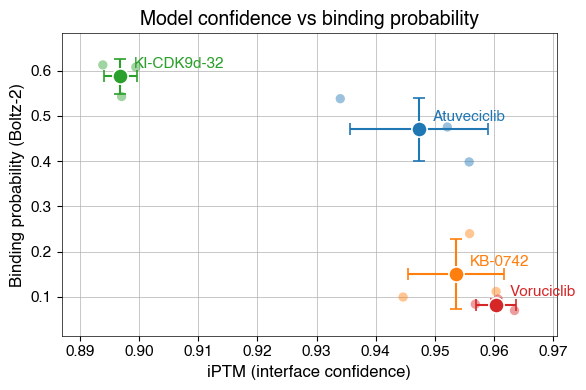

In [2]:
draw("S6e")

### 6f

12 rows


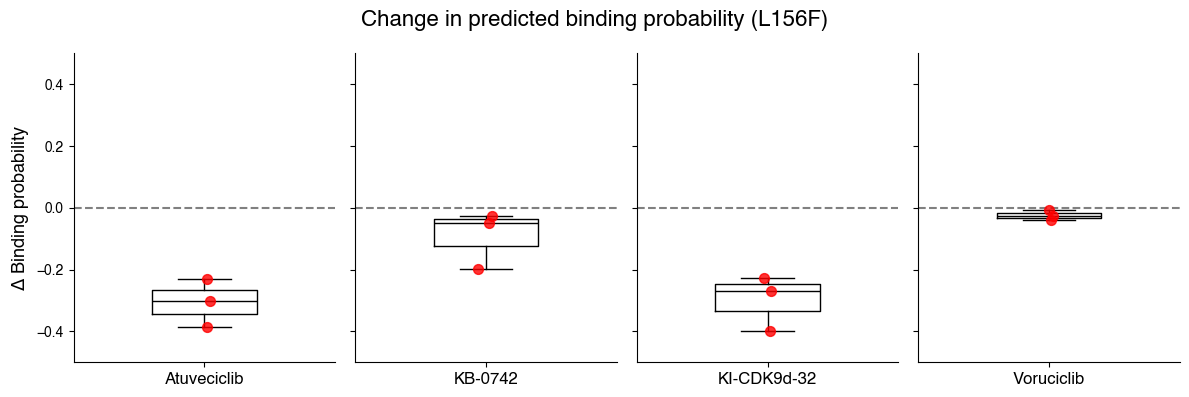

In [3]:
draw("S6f")

### 6h

36 rows


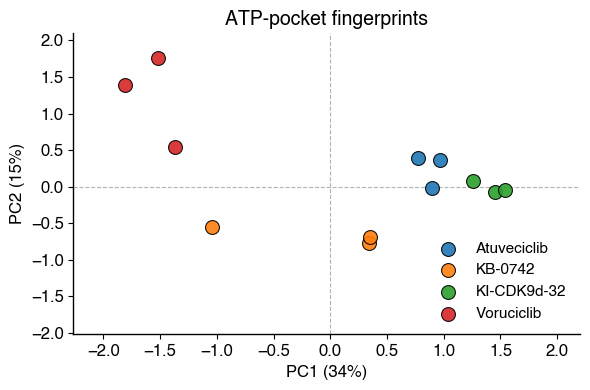

In [4]:
draw("S6h")

### 6i

10 rows


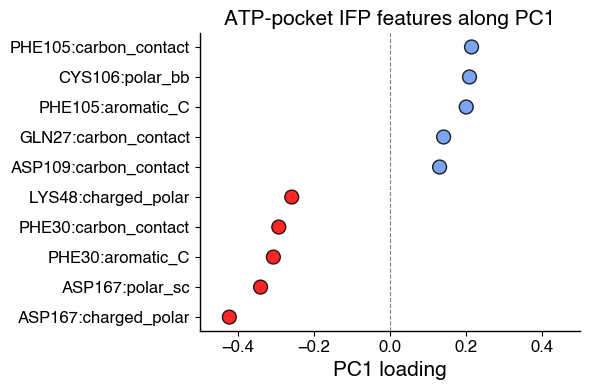

In [5]:
draw("S6i")

### 6j

10 rows


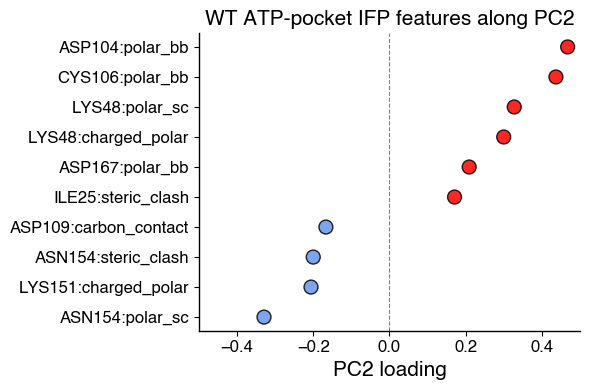

In [6]:
draw("S6j")

## Still to port

**6a**, **6b**, **6c**, **6d**, **6g**, **6k**, **6l**, **6m**

To port one: find the notebook or script that wrote its source file, move the
reduction into `cdkbe` and the drawing into `cdkbe.source_data`, then add it to
that module's `FIGURES`. `cdkbe.lollipop`, `cdkbe.heatmap`, `cdkbe.logo_panel`
and `cdkbe.dose_response` already cover most of the layouts.